In [109]:

import pandas as pd
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path




In [110]:

DATA_DIR = Path("data")

with zipfile.ZipFile(DATA_DIR / "events.zip") as archive:
    england_file = next(
        name for name in archive.namelist()
        if name.endswith("events_England.json")
    )

    with archive.open(england_file) as file:
        events = pd.read_json(file)

print("Total Premier League events:", len(events))
display(events.head())


Total Premier League events: 643150


,eventId,subEventName,tags,playerId,positions,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id
0,8,Simple pass,[{'id': 1801}],25413,"[{'y': 49, 'x': 49}, {'y': 78, 'x': 31}]",2499719,Pass,1609,1H,2.758649,85,177959171
1,8,High pass,[{'id': 1801}],370224,"[{'y': 78, 'x': 31}, {'y': 75, 'x': 51}]",2499719,Pass,1609,1H,4.946850,83,177959172
2,8,Head pass,[{'id': 1801}],3319,"[{'y': 75, 'x': 51}, {'y': 71, 'x': 35}]",2499719,Pass,1609,1H,6.542188,82,177959173
3,8,Head pass,[{'id': 1801}],120339,"[{'y': 71, 'x': 35}, {'y': 95, 'x': 41}]",2499719,Pass,1609,1H,8.143395,82,177959174
4,8,Simple pass,[{'id': 1801}],167145,"[{'y': 95, 'x': 41}, {'y': 88, 'x': 72}]",2499719,Pass,1609,1H,10.302366,85,177959175


In [111]:
united_id = 1611

united_events = events_england[events_england["teamId"] == united_id]

print(united_events["eventName"].value_counts())
print("Amount of matches:", united_events["matchId"].nunique())



eventName
Pass                       19372
Duel                        8789
Others on the ball          2501
Free Kick                   1811
Interruption                 811
Shot                         466
Foul                         421
Save attempt                 153
Offside                       87
Goalkeeper leaving line       40
Name: count, dtype: int64
Amount of matches: 38


In [112]:
#Splitting per 90
united_events = events[events["teamId"] == 1611]

#total of events / amount of games
per_90 = united_events["eventName"].value_counts() /38
print(per_90)


eventName
Pass                       509.789474
Duel                       231.289474
Others on the ball          65.815789
Free Kick                   47.657895
Interruption                21.342105
Shot                        12.263158
Foul                        11.078947
Save attempt                 4.026316
Offside                      2.289474
Goalkeeper leaving line      1.052632
Name: count, dtype: float64


In [113]:
#Each united players stats throughout the season
player_events = united_events.groupby(["playerId", "eventName"]).size()
player_events = player_events.unstack(fill_value=0)

display(player_events)

eventName,Duel,Foul,Free Kick,Goalkeeper leaving line,Interruption,Offside,Others on the ball,Pass,Save attempt,Shot
playerId,,,,,,,,,,
0,841,5,134,0,810,0,2,0,0,0
38,73,5,39,0,0,0,24,224,0,3
3361,356,10,34,0,0,10,67,580,0,15
3413,343,29,25,0,0,2,84,1024,0,12
7905,843,31,5,0,0,18,97,618,0,76
7906,254,11,107,0,0,19,105,1215,0,22
7910,9,0,380,39,0,0,38,621,150,0
7918,322,10,7,0,0,0,153,1057,0,2
7922,513,24,14,0,0,2,162,1071,0,12


In [114]:

#Count events for each player
player_events = (
    united_events
    .groupby(["playerId", "eventName"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

#Add player names and role
players["position"] = players["role"].apply(lambda x: x["name"])
player_events = player_events.merge(
    players[["wyId", "shortName", "position"]],
    left_on="playerId",
    right_on="wyId",
    how="left",
    validate="many_to_one"
)

#Remove the redundant ID column and NaN ID
player_events = player_events.drop(columns=["wyId"])
player_events = player_events[player_events["playerId"] != 0]


display(player_events.head(20))


,playerId,Duel,Foul,Free Kick,Goalkeeper leaving line,Interruption,Offside,Others on the ball,Pass,Save attempt,Shot,shortName,position
1,38,73,5,39,0,0,0,24,224,0,3,D. Blind,Defender
2,3361,356,10,34,0,0,10,67,580,0,15,A. S\u00e1nchez,Forward
3,3413,343,29,25,0,0,2,84,1024,0,12,Ander Herrera,Midfielder
4,7905,843,31,5,0,0,18,97,618,0,76,R. Lukaku,Forward
5,7906,254,11,107,0,0,19,105,1215,0,22,Juan Mata,Midfielder
6,7910,9,0,380,39,0,0,38,621,150,0,David de Gea,Goalkeeper
7,7918,322,10,7,0,0,0,153,1057,0,2,P. Jones,Defender
8,7922,513,24,14,0,0,2,162,1071,0,12,C. Smalling,Defender
9,7928,21,1,3,0,0,0,7,96,0,2,M. Carrick,Midfielder
10,7934,388,35,47,0,0,4,148,917,0,55,J. Lingard,Midfielder


In [115]:

#Load the Premier League matches dataset to grab player minutes
with zipfile.ZipFile("data/matches.zip", "r") as archive:
    england_file = next(
        name for name in archive.namelist()
        if name.endswith("matches_England.json")
    )

    with archive.open(england_file) as file:
        matches = pd.read_json(file)

print("Matches:", matches.shape)
print("Columns:", matches.columns.tolist())


Matches: (380, 14)
Columns: ['status', 'roundId', 'gameweek', 'teamsData', 'seasonId', 'dateutc', 'winner', 'venue', 'wyId', 'label', 'date', 'referees', 'duration', 'competitionId']


In [116]:

#Grabbing total minutes for each player
season_minutes = {}

#Going through every United game
for _, match in united_matches.iterrows():

    formation = match["teamsData"]["1611"]["formation"]
    starters = formation["lineup"]
    substitutions = formation["substitutions"]

    #Giving every starter 90 minutes
    minutes = {}

    for player in starters:
        minutes[player["playerId"]] = 90

    #Checking who got subbed off and on
    if not isinstance(substitutions, list):
        continue

    for sub in substitutions:
        minute = max(0, min(sub["minute"], 90))

        player_out = sub["playerOut"]
        player_in = sub["playerIn"]

        minutes[player_out] = minute
        minutes[player_in] = 90 - minute

    #Checking for red cards
    for player in starters + formation["bench"]:

        player_id = player["playerId"]
        red_card = player.get("redCards", 0)
        red_card = pd.to_numeric(red_card, errors="coerce")

        if pd.notna(red_card) and red_card > 0 and player_id in minutes:

            #Checking if they came on as a substitute
            start_minute = 0

            for sub in substitutions:
                if sub["playerIn"] == player_id:
                    start_minute = max(0, min(sub["minute"], 90))

            minutes[player_id] = max(0, min(red_card, 90) - start_minute)

    #Adding minutes from each game to season total
    for player_id in minutes:

        if player_id not in season_minutes:
            season_minutes[player_id] = 0

        season_minutes[player_id] += minutes[player_id]

#Making a dataframe with the total minutes
player_minutes = pd.DataFrame(
    list(season_minutes.items()),
    columns=["playerId", "minutes_played"]
)

display(player_minutes)


,playerId,minutes_played
0,7939,2447
1,38,360
2,7928,109
3,3361,1048
4,21095,443
5,101652,642
6,397174,630
7,397178,1805
8,20606,90
9,7906,1932


In [117]:
player_events = player_events.rename(
    columns={"playerId_x": "playerId"})

#Merging minutes with our United dataset
player_events = player_events.merge(
    player_minutes[["playerId", "minutes_played"]],
    on="playerId",
    how="left",
    validate="one_to_one"
)



display(player_events.head(20))

,playerId,Duel,Foul,Free Kick,Goalkeeper leaving line,Interruption,Offside,Others on the ball,Pass,Save attempt,Shot,shortName,position,minutes_played
0,38,73,5,39,0,0,0,24,224,0,3,D. Blind,Defender,360
1,3361,356,10,34,0,0,10,67,580,0,15,A. S\u00e1nchez,Forward,1048
2,3413,343,29,25,0,0,2,84,1024,0,12,Ander Herrera,Midfielder,1244
3,7905,843,31,5,0,0,18,97,618,0,76,R. Lukaku,Forward,2869
4,7906,254,11,107,0,0,19,105,1215,0,22,Juan Mata,Midfielder,1932
5,7910,9,0,380,39,0,0,38,621,150,0,David de Gea,Goalkeeper,3330
6,7918,322,10,7,0,0,0,153,1057,0,2,P. Jones,Defender,1975
7,7922,513,24,14,0,0,2,162,1071,0,12,C. Smalling,Defender,2535
8,7928,21,1,3,0,0,0,7,96,0,2,M. Carrick,Midfielder,109
9,7934,388,35,47,0,0,4,148,917,0,55,J. Lingard,Midfielder,1819


In [118]:
#per 90 per player
event_columns = united_events["eventName"].unique()

for event in event_columns:
    player_events[event + "_per90"] = (
        player_events[event] / player_events["minutes_played"] * 90
    )

display(player_events.head(20))



,playerId,Duel,Foul,Free Kick,Goalkeeper leaving line,Interruption,Offside,Others on the ball,Pass,Save attempt,...,Pass_per90,Duel_per90,Foul_per90,Others on the ball_per90,Free Kick_per90,Goalkeeper leaving line_per90,Shot_per90,Save attempt_per90,Offside_per90,Interruption_per90
0,38,73,5,39,0,0,0,24,224,0,...,56.000000,18.250000,1.250000,6.000000,9.750000,0.000000,0.750000,0.000000,0.000000,0.0
1,3361,356,10,34,0,0,10,67,580,0,...,49.809160,30.572519,0.858779,5.753817,2.919847,0.000000,1.288168,0.000000,0.858779,0.0
2,3413,343,29,25,0,0,2,84,1024,0,...,74.083601,24.815113,2.098071,6.077170,1.808682,0.000000,0.868167,0.000000,0.144695,0.0
3,7905,843,31,5,0,0,18,97,618,0,...,19.386546,26.444754,0.972464,3.042872,0.156849,0.000000,2.384106,0.000000,0.564657,0.0
4,7906,254,11,107,0,0,19,105,1215,0,...,56.599379,11.832298,0.512422,4.891304,4.984472,0.000000,1.024845,0.000000,0.885093,0.0
5,7910,9,0,380,39,0,0,38,621,150,...,16.783784,0.243243,0.000000,1.027027,10.270270,1.054054,0.000000,4.054054,0.000000,0.0
6,7918,322,10,7,0,0,0,153,1057,0,...,48.167089,14.673418,0.455696,6.972152,0.318987,0.000000,0.091139,0.000000,0.000000,0.0
7,7922,513,24,14,0,0,2,162,1071,0,...,38.023669,18.213018,0.852071,5.751479,0.497041,0.000000,0.426036,0.000000,0.071006,0.0
8,7928,21,1,3,0,0,0,7,96,0,...,79.266055,17.339450,0.825688,5.779817,2.477064,0.000000,1.651376,0.000000,0.000000,0.0
9,7934,388,35,47,0,0,4,148,917,0,...,45.371083,19.197361,1.731721,7.322705,2.325454,0.000000,2.721275,0.000000,0.197911,0.0


In [119]:

#Count events and calculate per 90 for every Premier League player

season_minutes = {}
valid_games = []

#Going through every Premier League game
for _, match in matches.iterrows():

    #Checking both teams in each game
    for team_id, team in match["teamsData"].items():

        formation = team["formation"]
        starters = formation["lineup"]
        substitutions = formation["substitutions"]

        #Skipping games with missing information
        if not isinstance(starters, list) or not isinstance(substitutions, list):
            continue

        valid_games.append({
            "matchId": match["wyId"],
            "teamId": int(team_id)
        })

        #Giving each starter 90 minutes
        minutes = {}

        for player in starters:
            minutes[player["playerId"]] = 90

        #Checking who got subbed off and on
        for sub in substitutions:
            minute = max(0, min(sub["minute"], 90))

            player_out = sub["playerOut"]
            player_in = sub["playerIn"]

            minutes[player_out] = minute
            minutes[player_in] = 90 - minute

        #Checking for red cards
        for player in starters + formation["bench"]:

            player_id = player["playerId"]
            red_card = player.get("redCards", 0)
            red_card = pd.to_numeric(red_card, errors="coerce")

            if pd.notna(red_card) and red_card > 0 and player_id in minutes:

                #Checking if they came on as a substitute
                start_minute = 0

                for sub in substitutions:
                    if sub["playerIn"] == player_id:
                        start_minute = max(0, min(sub["minute"], 90))

                minutes[player_id] = max(0, min(red_card, 90) - start_minute)

        #Adding each player's minutes to their season total
        for player_id in minutes:

            if player_id not in season_minutes:
                season_minutes[player_id] = 0

            season_minutes[player_id] += minutes[player_id]

#Making a dataframe with total minutes
league_minutes = pd.DataFrame(
    list(season_minutes.items()),
    columns=["playerId", "minutes_played"]
)

#Only counting events from games included in our minutes
valid_games = pd.DataFrame(valid_games)

league_data = events.merge(
    valid_games,
    on=["matchId", "teamId"],
    how="inner"
)

#Counting events for each player
league_events = (
    league_data
    .groupby(["playerId", "eventName"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

#Adding player names and positions
league_events = league_events.merge(
    players[["wyId", "shortName", "position"]],
    left_on="playerId",
    right_on="wyId",
    how="left"
)

#Removing redundant ID and unidentified players
league_events = league_events.drop(columns=["wyId"])
league_events = league_events[league_events["playerId"] != 0]

#Adding total minutes played
league_events = league_events.merge(
    league_minutes,
    on="playerId",
    how="left",
    validate="one_to_one"
)

#Keeping players with recorded playing time
league_events = league_events[
    league_events["minutes_played"] > 0
].copy()

#Calculating every event per 90 minutes
event_columns = league_data["eventName"].unique()

for event in event_columns:
    league_events[event + "_per90"] = (
        league_events[event] / league_events["minutes_played"] * 90
    )

#Checking our results
print("Total matches:", len(matches))
print("Team-game records used:", len(valid_games))
print("Total players:", len(league_events))
print("Total player minutes:", league_minutes["minutes_played"].sum())

display(league_events.head(20))


Total matches: 380
Team-game records used: 755
Total players: 512
Total player minutes: 746417


,playerId,Duel,Foul,Free Kick,Goalkeeper leaving line,Interruption,Offside,Others on the ball,Pass,Save attempt,...,Pass_per90,Duel_per90,Foul_per90,Free Kick_per90,Shot_per90,Save attempt_per90,Others on the ball_per90,Interruption_per90,Goalkeeper leaving line_per90,Offside_per90
0,36,182,9,28,0,0,0,118,898,0,...,68.724490,13.928571,0.688776,2.142857,0.765306,0.0,9.030612,0.0,0.0,0.000000
1,38,73,5,39,0,0,0,24,224,0,...,56.000000,18.250000,1.250000,9.750000,0.750000,0.0,6.000000,0.0,0.0,0.000000
2,48,602,20,68,0,0,1,309,2370,0,...,66.573034,16.910112,0.561798,1.910112,0.646067,0.0,8.679775,0.0,0.0,0.028090
3,54,601,14,251,0,0,1,265,2196,0,...,61.264724,16.766894,0.390577,7.002480,2.231866,0.0,7.393056,0.0,0.0,0.027898
4,56,46,5,1,0,0,0,12,97,0,...,34.920000,16.560000,1.800000,0.360000,0.360000,0.0,4.320000,0.0,0.0,0.000000
5,74,248,7,25,0,0,0,118,1130,0,...,70.234807,15.414365,0.435083,1.553867,0.124309,0.0,7.334254,0.0,0.0,0.000000
6,93,607,18,160,0,0,2,171,810,0,...,26.528384,19.879913,0.589520,5.240175,1.572052,0.0,5.600437,0.0,0.0,0.065502
7,107,613,60,238,0,0,2,231,1041,0,...,34.444853,20.283088,1.985294,7.875000,0.099265,0.0,7.643382,0.0,0.0,0.066176
8,116,462,12,16,0,0,4,150,1225,0,...,46.168342,17.412060,0.452261,0.603015,1.356784,0.0,5.653266,0.0,0.0,0.150754
9,120,58,3,1,0,0,2,8,45,0,...,18.080357,23.303571,1.205357,0.401786,1.607143,0.0,3.214286,0.0,0.0,0.803571


In [120]:

#Creating a more detailed passing table
passes = league_data[league_data["eventName"] == "Pass"].copy()

#Getting the starting and ending positions of each pass
passes = passes[passes["positions"].apply(
    lambda x: isinstance(x, list) and len(x) >= 2
)].copy()

passes["start_x"] = passes["positions"].apply(lambda x: x[0]["x"])
passes["end_x"] = passes["positions"].apply(lambda x: x[1]["x"])

#Checking if the pass was accurate
passes["accurate"] = passes["tags"].apply(
    lambda x: any(tag["id"] == 1801 for tag in x)
)

#Checking pass direction
passes["forward"] = passes["end_x"] > passes["start_x"]
passes["backward"] = passes["end_x"] < passes["start_x"]

#Counting passes for each player
in_depth90 = passes.groupby("playerId").agg(
    Pass_Attempts=("accurate", "size"),
    Successful_Passes=("accurate", "sum"),
    Forward_Passes=("forward", "sum"),
    Backward_Passes=("backward", "sum")
).reset_index()

#Calculating unsuccessful passes
in_depth90["Unsuccessful_Passes"] = (
    in_depth90["Pass_Attempts"] - in_depth90["Successful_Passes"]
)

#Adding names, positions, and minutes
in_depth90 = in_depth90.merge(
    players[["wyId", "shortName", "position"]],
    left_on="playerId",
    right_on="wyId",
    how="left"
)

in_depth90 = in_depth90.drop(columns=["wyId"])
in_depth90 = in_depth90[in_depth90["playerId"] != 0]

in_depth90 = in_depth90.merge(
    league_minutes,
    on="playerId",
    how="left"
)

#Keeping players with recorded minutes
in_depth90 = in_depth90[
    in_depth90["minutes_played"] > 0
].copy()

#Calculating pass accuracy
in_depth90["Pass_Accuracy"] = (
    in_depth90["Successful_Passes"] / in_depth90["Pass_Attempts"] * 100
)

#Calculating passing statistics per 90
pass_columns = [
    "Pass_Attempts",
    "Successful_Passes",
    "Unsuccessful_Passes",
    "Forward_Passes",
    "Backward_Passes"
]

for column in pass_columns:
    in_depth90[column + "_per90"] = (
        in_depth90[column] / in_depth90["minutes_played"] * 90
    )

display(in_depth90.head(20))


,playerId,Pass_Attempts,Successful_Passes,Forward_Passes,Backward_Passes,Unsuccessful_Passes,shortName,position,minutes_played,Pass_Accuracy,Pass_Attempts_per90,Successful_Passes_per90,Unsuccessful_Passes_per90,Forward_Passes_per90,Backward_Passes_per90
0,36,898,790,678,197,108,T. Alderweireld,Defender,1176,87.973274,68.724490,60.459184,8.265306,51.887755,15.076531
1,38,224,192,139,81,32,D. Blind,Defender,360,85.714286,56.000000,48.000000,8.000000,34.750000,20.250000
2,48,2370,2113,1721,561,257,J. Vertonghen,Defender,3204,89.156118,66.573034,59.353933,7.219101,48.342697,15.758427
3,54,2196,1803,1234,885,393,C. Eriksen,Midfielder,3226,82.103825,61.264724,50.300682,10.964042,34.426534,24.690019
4,56,97,78,49,44,19,D. Klaassen,Midfielder,250,80.412371,34.920000,28.080000,6.840000,17.640000,15.840000
5,74,1130,1052,817,256,78,R. Klavan,Defender,1448,93.097345,70.234807,65.386740,4.848066,50.780387,15.911602
6,93,810,595,424,354,215,J. Gu\u00f0munds\u00adson,Midfielder,2748,73.456790,26.528384,19.486900,7.041485,13.886463,11.593886
7,107,1041,771,636,379,270,E. Pieters,Defender,2720,74.063401,34.444853,25.511029,8.933824,21.044118,12.540441
8,116,1225,1114,624,560,111,G. Wijnaldum,Midfielder,2388,90.938776,46.168342,41.984925,4.183417,23.517588,21.105528
9,120,45,31,25,17,14,J. Locadia,Forward,224,68.888889,18.080357,12.455357,5.625000,10.044643,6.830357


In [121]:

#Getting smart passes for every Premier League player
smart_passes = league_data[
    league_data["subEventName"] == "Smart pass"
].copy()

#Checking which smart passes were successful
smart_passes["accurate"] = smart_passes["tags"].apply(
    lambda x: any(tag["id"] == 1801 for tag in x)
)

#Counting smart passes for each player
smart_stats = smart_passes.groupby("playerId").agg(
    Smart_Passes=("accurate", "size"),
    Successful_Smart_Passes=("accurate", "sum")
).reset_index()

#Adding smart pass statistics to our existing table
in_depth90 = in_depth90.merge(
    smart_stats,
    on="playerId",
    how="left",
    validate="one_to_one"
)

#Replacing missing values with zero
in_depth90["Smart_Passes"] = in_depth90["Smart_Passes"].fillna(0)
in_depth90["Successful_Smart_Passes"] = in_depth90["Successful_Smart_Passes"].fillna(0)

#Calculating smart passes per 90
in_depth90["Smart_Passes_per90"] = (
    in_depth90["Smart_Passes"] / in_depth90["minutes_played"] * 90
)

in_depth90["Successful_Smart_Passes_per90"] = (
    in_depth90["Successful_Smart_Passes"] / in_depth90["minutes_played"] * 90
)

#Calculating smart pass accuracy
in_depth90["Smart_Pass_Accuracy"] = (
    in_depth90["Successful_Smart_Passes"] / in_depth90["Smart_Passes"] * 100
)

#Showing the new statistics
display(in_depth90[[
    "shortName",
    "position",
    "minutes_played",
    "Smart_Passes",
    "Smart_Passes_per90",
    "Successful_Smart_Passes_per90",
    "Smart_Pass_Accuracy"
]].head(20))


,shortName,position,minutes_played,Smart_Passes,Smart_Passes_per90,Successful_Smart_Passes_per90,Smart_Pass_Accuracy
0,T. Alderweireld,Defender,1176,3.0,0.229592,0.076531,33.333333
1,D. Blind,Defender,360,1.0,0.250000,0.250000,100.000000
2,J. Vertonghen,Defender,3204,13.0,0.365169,0.084270,23.076923
3,C. Eriksen,Midfielder,3226,111.0,3.096714,1.171730,37.837838
4,D. Klaassen,Midfielder,250,2.0,0.720000,0.360000,50.000000
5,R. Klavan,Defender,1448,5.0,0.310773,0.248619,80.000000
6,J. Gu\u00f0munds\u00adson,Midfielder,2748,17.0,0.556769,0.196507,35.294118
7,E. Pieters,Defender,2720,12.0,0.397059,0.066176,16.666667
8,G. Wijnaldum,Midfielder,2388,12.0,0.452261,0.075377,16.666667
9,J. Locadia,Forward,224,3.0,1.205357,0.803571,66.666667


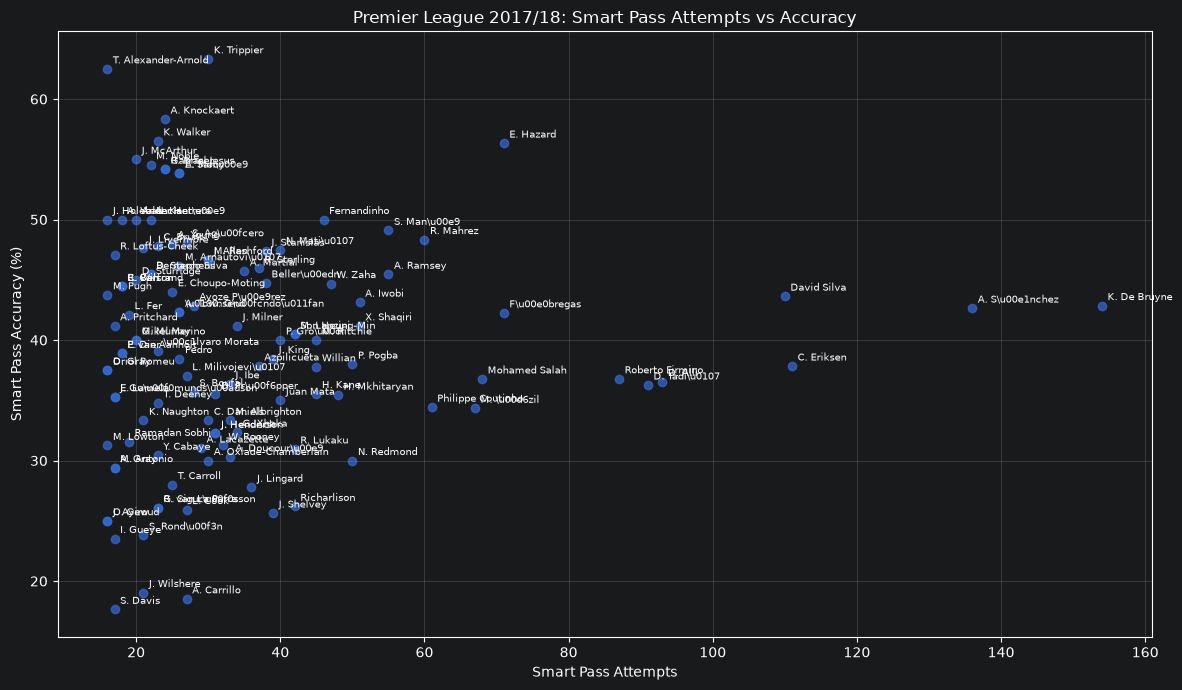

In [122]:

#Visualizing smart pass attempts vs accuracy

#Only including players with more than 15 attempts
smart_plot = in_depth90[in_depth90["Smart_Passes"] > 15]

#Creating scatter plot
plt.figure(figsize=(12, 7))

plt.scatter(
    smart_plot["Smart_Passes"],
    smart_plot["Smart_Pass_Accuracy"],
    alpha=0.7
)

#Adding player names
for _, player in smart_plot.iterrows():
    plt.annotate(
        player["shortName"],
        (player["Smart_Passes"], player["Smart_Pass_Accuracy"]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points"
    )

#Adding labels
plt.xlabel("Smart Pass Attempts")
plt.ylabel("Smart Pass Accuracy (%)")
plt.title("Premier League 2017/18: Smart Pass Attempts vs Accuracy")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [156]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

#Creating our ML dataset
ml_data = in_depth90.merge(
    league_events[["playerId", "Duel_per90", "Shot_per90"]],
    on="playerId",
    how="left",
    validate="one_to_one"
)

#Choosing the features for our model
features = [
    "Pass_Attempts_per90",
    "Pass_Accuracy",
    "Forward_Passes_per90",
    "Smart_Passes_per90",
    "Duel_per90",
    "Shot_per90"
]

#Only comparing forwards who played at least 900 minutes
ml_data = ml_data[
    (ml_data["position"] == "Defender") &
    (ml_data["minutes_played"] >= 900)
].copy()

#Removing players with missing feature values
ml_data = ml_data.dropna(subset=features).reset_index(drop=True)

#Standardizing the features
scaler = StandardScaler()
X = scaler.fit_transform(ml_data[features])

#Creating our nearest neighbor model
knn = NearestNeighbors(
    n_neighbors=6,
    metric="euclidean"
)

knn.fit(X)

#Finding Kieran Trippier
trippier = ml_data[
    ml_data["shortName"].str.contains("Trippier", case=False, na=False)
]

if len(trippier) == 1:
    trippier_id = trippier.iloc[0]["playerId"]
    trippier_index = trippier.index[0]

    #Displaying Kieran Trippier's statistics
    print("Kieran Trippier's Statistics:")
    display(trippier[
        ["shortName", "position", "minutes_played"] + features
    ])

    #Finding the nearest players
    distances, indices = knn.kneighbors(
        X[trippier_index].reshape(1, -1)
    )

    #Getting the 5 closest players (excluding Trippier)
    similar_players = ml_data.iloc[indices[0]].copy()
    similar_players["Distance"] = distances[0]

    similar_players = similar_players[
        similar_players["playerId"] != trippier_id
    ].head(5)

    #Fixing Hector Bellerin's name
    similar_players.loc[
    similar_players["shortName"].str.contains("Beller", case=False, na=False),
    "shortName"
    ] = "Héctor Bellerín"

    #Displaying our results
    print("Five Most Similar Players:")
    display(similar_players[
        ["shortName", "position", "minutes_played"] +
        features + ["Distance"]
    ])

else:
    print("Could not find exactly one Kieran Trippier in ml_data.")

Kieran Trippier's Statistics:


,shortName,position,minutes_played,Pass_Attempts_per90,Pass_Accuracy,Forward_Passes_per90,Smart_Passes_per90,Duel_per90,Shot_per90
61,K. Trippier,Defender,1915,61.613577,79.938978,30.313316,1.409922,17.718016,0.281984


Five Most Similar Players:


,shortName,position,minutes_played,Pass_Attempts_per90,Pass_Accuracy,Forward_Passes_per90,Smart_Passes_per90,Duel_per90,Shot_per90,Distance
28,A. Young,Defender,2447,50.020433,79.117647,30.049040,0.919493,18.978341,0.514916,2.206517
119,T. Alexander-Arnold,Defender,1576,61.332487,77.001862,34.321066,0.913706,15.989848,0.571066,2.255768
108,Héctor Bellerín,Defender,2961,55.562310,84.956236,26.231003,1.155015,17.933131,0.851064,2.315763
67,C. Daniels,Defender,3006,47.335329,78.874130,28.712575,0.898204,14.341317,0.508982,2.561250
86,Azpilicueta,Defender,3330,73.324324,86.951714,48.621622,1.000000,16.432432,0.324324,2.732540


In [160]:
#Finding Trippier and Aurier
import numpy as np
trippier_index = ml_data[
    ml_data["shortName"].str.contains("Trippier", case=False, na=False)
].index[0]

aurier_index = ml_data[
    ml_data["shortName"].str.contains("Aurier", case=False, na=False)
].index[0]

#Calculating the Euclidean distance between them
distance = np.linalg.norm(
    X[trippier_index] - X[aurier_index]
)

#Displaying their statistics
display(ml_data.loc[
    [trippier_index, aurier_index],
    ["shortName", "position", "minutes_played"] + features
].round(2))

#Displaying their distance
print("Trippier - Aurier Euclidean Distance:", round(distance, 3))

,shortName,position,minutes_played,Pass_Attempts_per90,Pass_Accuracy,Forward_Passes_per90,Smart_Passes_per90,Duel_per90,Shot_per90
61,K. Trippier,Defender,1915,61.61,79.94,30.31,1.41,17.72,0.28
87,S. Aurier,Defender,1429,51.39,79.29,27.33,0.76,25.51,0.94


Trippier - Aurier Euclidean Distance: 4.224


In [165]:
import numpy as np
import pandas as pd

#Finding Trippier and Aurier
trippier = ml_data[
    ml_data["shortName"].str.contains("Trippier", case=False, na=False)
]

aurier = ml_data[
    ml_data["shortName"].str.contains("Aurier", case=False, na=False)
]

#Finding Kyle Walker-Peters in the original dataset
walker_peters = players[
    players["shortName"].str.contains("Walker", case=False, na=False) &
    players["shortName"].str.contains("Peters", case=False, na=False)
]

if len(trippier) == 1 and len(aurier) == 1 and len(walker_peters) == 1:

    #Getting Walker-Peters' statistics
    walker_peters_id = walker_peters.iloc[0]["wyId"]

    walker_peters_stats = in_depth90[
        in_depth90["playerId"] == walker_peters_id
    ].merge(
        league_events[["playerId", "Duel_per90", "Shot_per90"]],
        on="playerId",
        how="left"
    )

    if len(walker_peters_stats) == 1 and walker_peters_stats[features].notna().all().all():

        #Standardizing all players using our existing scaler
        trippier_scaled = scaler.transform(trippier[features])
        aurier_scaled = scaler.transform(aurier[features])
        walker_peters_scaled = scaler.transform(walker_peters_stats[features])

        #Calculating distances to Trippier
        aurier_distance = np.linalg.norm(
            trippier_scaled[0] - aurier_scaled[0]
        )

        walker_peters_distance = np.linalg.norm(
            trippier_scaled[0] - walker_peters_scaled[0]
        )

        #Combining Aurier and Walker-Peters
        comparison = pd.concat(
            [aurier, walker_peters_stats],
            ignore_index=True
        )

        #Adding their distances to Trippier
        comparison["Distance_to_Trippier"] = [
            aurier_distance,
            walker_peters_distance
        ]

        #Displaying both players in one table
        print("Serge Aurier and Kyle Walker-Peters Compared to Kieran Trippier")

        display(comparison[
            ["shortName", "position", "minutes_played"] +
            features + ["Distance_to_Trippier"]
        ].round(3))

    else:
        print("Walker-Peters has missing performance statistics.")

else:
    print("Could not find exactly one Trippier, Aurier, and Walker-Peters.")

Serge Aurier and Kyle Walker-Peters Compared to Kieran Trippier


,shortName,position,minutes_played,Pass_Attempts_per90,Pass_Accuracy,Forward_Passes_per90,Smart_Passes_per90,Duel_per90,Shot_per90,Distance_to_Trippier
0,S. Aurier,Defender,1429,51.393,79.289,27.334,0.756,25.507,0.945,4.224
1,K. Walker-Peters,Defender,188,49.787,83.654,22.021,0.000,30.638,0.000,6.969


Players compared to Kieran Trippier:


,shortName,position,minutes_played,Pass_Attempts_per90,Pass_Accuracy,Forward_Passes_per90,Smart_Passes_per90,Duel_per90,Shot_per90,Distance_to_Trippier
0,A. Young,Defender,2447,50.020,79.118,30.049,0.919,18.978,0.515,2.207
1,T. Alexander-Arnold,Defender,1576,61.332,77.002,34.321,0.914,15.990,0.571,2.256
2,Héctor Bellerín,Defender,2961,55.562,84.956,26.231,1.155,17.933,0.851,2.316
3,C. Daniels,Defender,3006,47.335,78.874,28.713,0.898,14.341,0.509,2.561
4,Azpilicueta,Defender,3330,73.324,86.952,48.622,1.000,16.432,0.324,2.733
5,S. Aurier,Defender,1429,51.393,79.289,27.334,0.756,25.507,0.945,4.224
6,K. Walker-Peters,Defender,188,49.787,83.654,22.021,0.000,30.638,0.000,6.969


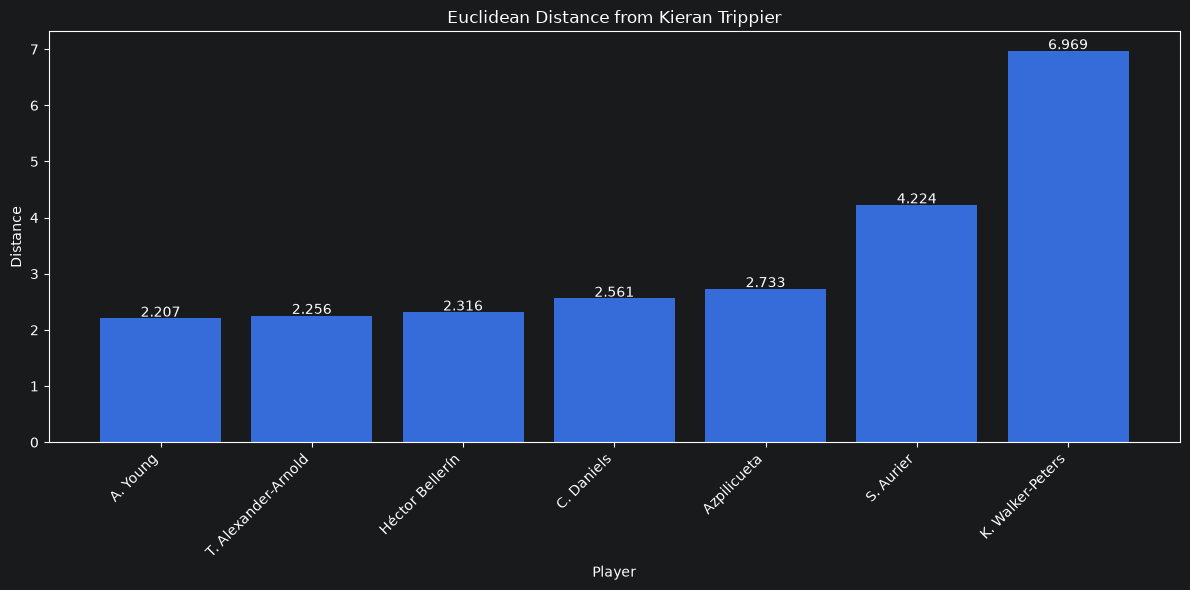

In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


#Find Kieran Trippier

trippier = ml_data[
    ml_data["shortName"].str.contains("Trippier", case=False, na=False)
].copy()

if len(trippier) != 1:
    print("Could not find exactly one Kieran Trippier in ml_data.")

else:
    trippier_id = trippier.iloc[0]["playerId"]
    trippier_index = trippier.index[0]

    #Rebuild / confirm top 5 nearest neighbors

    distances, indices = knn.kneighbors(
        X[trippier_index].reshape(1, -1)
    )

    similar_players = ml_data.iloc[indices[0]].copy()
    similar_players["Distance_to_Trippier"] = distances[0]

    similar_players = similar_players[
        similar_players["playerId"] != trippier_id
    ].head(5).copy()

    #Fix Bellerin display name
    similar_players.loc[
        similar_players["shortName"].str.contains("Beller", case=False, na=False),
        "shortName"
    ] = "Héctor Bellerín"

    #Keep only the columns we want
    top5_table = similar_players[
        ["shortName", "position", "minutes_played"] + features + ["Distance_to_Trippier"]
    ].copy()


    #Get Serge Aurier and calculate his distance to Trippier

    aurier = ml_data[
        ml_data["shortName"].str.contains("Aurier", case=False, na=False)
    ].copy()

    extra_rows = []

    if len(aurier) == 1:
        aurier_scaled = scaler.transform(aurier[features])
        aurier_distance = np.linalg.norm(
            X[trippier_index] - aurier_scaled[0]
        )

        aurier_row = aurier[
            ["shortName", "position", "minutes_played"] + features
        ].copy()
        aurier_row["Distance_to_Trippier"] = aurier_distance
        extra_rows.append(aurier_row)
    else:
        print("Could not find exactly one Serge Aurier in ml_data.")


    #Get Kyle Walker-Peters and calculate his distance to Trippier

    walker_peters_player = players[
        players["shortName"].str.contains("Walker", case=False, na=False) &
        players["shortName"].str.contains("Peters", case=False, na=False)
    ].copy()

    if len(walker_peters_player) == 1:
        walker_peters_id = walker_peters_player.iloc[0]["wyId"]

        walker_peters_stats = in_depth90[
            in_depth90["playerId"] == walker_peters_id
        ].merge(
            league_events[["playerId", "Duel_per90", "Shot_per90"]],
            on="playerId",
            how="left"
        )

        if len(walker_peters_stats) == 1 and walker_peters_stats[features].notna().all().all():
            walker_peters_scaled = scaler.transform(
                walker_peters_stats[features]
            )

            walker_peters_distance = np.linalg.norm(
                X[trippier_index] - walker_peters_scaled[0]
            )

            walker_peters_row = walker_peters_stats[
                ["shortName", "position", "minutes_played"] + features
            ].copy()
            walker_peters_row["Distance_to_Trippier"] = walker_peters_distance
            extra_rows.append(walker_peters_row)
        else:
            print("Walker-Peters is missing one or more features.")
    else:
        print("Could not identify exactly one Kyle Walker-Peters.")

    #Combine top 5 + Aurier + Walker-Peters

    if len(extra_rows) > 0:
        extras_table = pd.concat(extra_rows, ignore_index=True)
        plot_table = pd.concat([top5_table, extras_table], ignore_index=True)
    else:
        plot_table = top5_table.copy()

    #Sort by distance for cleaner plotting
    plot_table = plot_table.sort_values(
        "Distance_to_Trippier"
    ).reset_index(drop=True)


    #Display the table

    print("Players compared to Kieran Trippier:")
    display(plot_table.round(3))


    plt.figure(figsize=(12, 6))
    plt.bar(
        plot_table["shortName"],
        plot_table["Distance_to_Trippier"]
    )

    plt.title("Euclidean Distance from Kieran Trippier")
    plt.xlabel("Player")
    plt.ylabel("Distance")
    plt.xticks(rotation=45, ha="right")

    for i, value in enumerate(plot_table["Distance_to_Trippier"]):
        plt.text(i, value + 0.03, round(value, 3), ha="center")

    plt.tight_layout()
    plt.show()